# M Dim Ablation

This notebook compares M embedding dimensions using averaged multi-seed PCA query projection runs.

## Setup

The notebook reads the grouped experiment result from `output/summary.json`.

In [1]:
from __future__ import annotations

import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

OUTPUT_DIR = Path("output")
SUMMARY_PATH = OUTPUT_DIR / "summary.json"

plt.rcParams.update(
    {
        "figure.dpi": 150,
        "savefig.dpi": 300,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "axes.edgecolor": "#D1D5DB",
        "axes.labelcolor": "#111827",
        "axes.titlesize": 14,
        "axes.titleweight": "bold",
        "axes.labelsize": 11,
        "xtick.color": "#374151",
        "ytick.color": "#374151",
        "grid.color": "#E5E7EB",
        "grid.linewidth": 0.8,
        "legend.frameon": False,
        "font.size": 10,
    }
)

SPLIT_COLORS = {
    "dev": "#2563EB",
    "test": "#059669",
    "xeval": "#D97706",
}


## Load Results

The aggregate table contains one averaged row per M dimension.

In [2]:
with SUMMARY_PATH.open("r", encoding="utf-8") as file:
    summary = json.load(file)

runs = summary["runs"]
aggregates = summary["aggregate"]


def flatten_aggregate(item: dict) -> dict:
    row = {
        "m_dim": item["m_dim"],
        "num_seeds": item["num_seeds"],
        "best_epoch": item["best_epoch"],
    }

    for split_name in ("best_dev", "test", "xeval"):
        for metric_name in ("loss", "top1", "ndcg"):
            row[f"{split_name}_{metric_name}"] = item[split_name][metric_name]

    return row


aggregate_df = pd.DataFrame([flatten_aggregate(item) for item in aggregates])
aggregate_df = aggregate_df.sort_values("m_dim").reset_index(drop=True)

display(aggregate_df)


,m_dim,num_seeds,best_epoch,best_dev_loss,best_dev_top1,best_dev_ndcg,test_loss,test_top1,test_ndcg,xeval_loss,xeval_top1,xeval_ndcg
0,0,5,1.8,1.610649,0.035714,0.692463,1.610878,0.178571,0.728734,1.608733,0.248291,0.755067
1,8,5,14.0,1.601836,0.414286,0.795372,1.601831,0.242857,0.776055,1.612415,0.170513,0.718861
2,16,5,13.0,1.601619,0.392857,0.785523,1.599385,0.271429,0.785279,1.611124,0.183761,0.726566
3,32,5,17.0,1.595816,0.385714,0.785714,1.593928,0.285714,0.794132,1.611238,0.187179,0.727204
4,64,5,14.8,1.596396,0.385714,0.789381,1.594037,0.300000,0.794893,1.610514,0.182051,0.727360
5,128,5,18.0,1.593013,0.414286,0.796743,1.590009,0.292857,0.804786,1.609710,0.193162,0.733480
6,256,5,17.6,1.592281,0.407143,0.795384,1.589774,0.350000,0.811693,1.608189,0.186752,0.735631


## Per-Seed Results

This table keeps the raw seed-level results available for inspection.

In [3]:
def best_epoch_from_history(run: dict) -> int:
    history = run["history"]
    best_item = max(history, key=lambda item: item["dev"]["ndcg"])
    return int(best_item["epoch"])


seed_records = []
for run in runs:
    experiment = run["experiment"]
    best_dev = run["best_dev"]
    test = run["test"]
    xeval = run["xeval"]

    seed_records.append(
        {
            "run": experiment["name"],
            "m_dim": experiment["m_embedding_dim"],
            "seed": experiment["seed"],
            "best_epoch": best_epoch_from_history(run),
            "best_dev_top1": best_dev["top1"],
            "best_dev_ndcg": best_dev["ndcg"],
            "test_top1": test["top1"],
            "test_ndcg": test["ndcg"],
            "xeval_top1": xeval["top1"],
            "xeval_ndcg": xeval["ndcg"],
        }
    )

seed_df = pd.DataFrame(seed_records).sort_values(["m_dim", "seed"]).reset_index(drop=True)
display(seed_df)


,run,m_dim,seed,best_epoch,best_dev_top1,best_dev_ndcg,test_top1,test_ndcg,xeval_top1,xeval_ndcg
0,m0,0,7,1,0.035714,0.691830,0.178571,0.728669,0.252137,0.756021
1,m0,0,13,1,0.035714,0.693559,0.178571,0.728018,0.252137,0.756458
2,m0,0,21,1,0.035714,0.692370,0.178571,0.728669,0.245726,0.753682
3,m0,0,42,5,0.035714,0.693305,0.178571,0.729645,0.239316,0.752917
4,m0,0,100,1,0.035714,0.691252,0.178571,0.728669,0.252137,0.756258
5,m8,8,7,9,0.392857,0.795057,0.214286,0.769160,0.166667,0.719081
6,m8,8,13,7,0.392857,0.792243,0.285714,0.779544,0.160256,0.726163
7,m8,8,21,15,0.392857,0.783360,0.214286,0.769650,0.192308,0.721681
8,m8,8,42,19,0.428571,0.803617,0.250000,0.780888,0.166667,0.714081
9,m8,8,100,20,0.464286,0.802581,0.250000,0.781033,0.166667,0.713298


## Metrics

Top-1 and nDCG values are shown as percentages.

In [4]:
metric_rows = []
for _, row in aggregate_df.iterrows():
    metric_rows.append(
        {
            "m_dim": int(row["m_dim"]),
            "seeds": int(row["num_seeds"]),
            "best_epoch": f"{row['best_epoch']:.1f}",
            "dev_top1": 100.0 * row["best_dev_top1"],
            "dev_ndcg": 100.0 * row["best_dev_ndcg"],
            "test_top1": 100.0 * row["test_top1"],
            "test_ndcg": 100.0 * row["test_ndcg"],
            "xeval_top1": 100.0 * row["xeval_top1"],
            "xeval_ndcg": 100.0 * row["xeval_ndcg"],
        }
    )

metrics_df = pd.DataFrame(metric_rows)
display(
    metrics_df.style.format(
        {
            "dev_top1": "{:.2f}",
            "dev_ndcg": "{:.2f}",
            "test_top1": "{:.2f}",
            "test_ndcg": "{:.2f}",
            "xeval_top1": "{:.2f}",
            "xeval_ndcg": "{:.2f}",
        }
    )
    .background_gradient(subset=["dev_ndcg", "test_ndcg", "xeval_ndcg"], cmap="Blues")
    .background_gradient(subset=["dev_top1", "test_top1", "xeval_top1"], cmap="Greens")
)


,m_dim,seeds,best_epoch,dev_top1,dev_ndcg,test_top1,test_ndcg,xeval_top1,xeval_ndcg
0,0,5,1.8,3.57,69.25,17.86,72.87,24.83,75.51
1,8,5,14.0,41.43,79.54,24.29,77.61,17.05,71.89
2,16,5,13.0,39.29,78.55,27.14,78.53,18.38,72.66
3,32,5,17.0,38.57,78.57,28.57,79.41,18.72,72.72
4,64,5,14.8,38.57,78.94,30.00,79.49,18.21,72.74
5,128,5,18.0,41.43,79.67,29.29,80.48,19.32,73.35
6,256,5,17.6,40.71,79.54,35.00,81.17,18.68,73.56


## Best Setting

The selected setting is the highest averaged dev nDCG, with averaged dev Top-1 as the secondary signal.

In [5]:
best = aggregate_df.sort_values(
    ["best_dev_ndcg", "best_dev_top1", "m_dim"],
    ascending=[False, False, True],
).iloc[0]

print(f"best M dim: {int(best.m_dim)}")
print(f"seeds: {int(best.num_seeds)}")
print(f"best epoch: {best.best_epoch:.1f}")
print(f"dev top1: {best.best_dev_top1:.4f}")
print(f"dev ndcg: {best.best_dev_ndcg:.4f}")
print(f"test top1: {best.test_top1:.4f}")
print(f"test ndcg: {best.test_ndcg:.4f}")
print(f"xeval top1: {best.xeval_top1:.4f}")
print(f"xeval ndcg: {best.xeval_ndcg:.4f}")


best M dim: 128
seeds: 5
best epoch: 18.0
dev top1: 0.4143
dev ndcg: 0.7967
test top1: 0.2929
test ndcg: 0.8048
xeval top1: 0.1932
xeval ndcg: 0.7335


## Delta

Each M dimension is compared against the no-M baseline `m0`.

In [6]:
baseline = aggregate_df[aggregate_df["m_dim"] == 0].iloc[0]

delta = aggregate_df[["m_dim"]].copy()
for col in [
    "best_dev_top1",
    "best_dev_ndcg",
    "test_top1",
    "test_ndcg",
    "xeval_top1",
    "xeval_ndcg",
]:
    delta[col + "_delta"] = 100.0 * (aggregate_df[col] - baseline[col])

display(
    delta.style.format({col: "{:+.2f}" for col in delta.columns if col != "m_dim"})
    .background_gradient(
        subset=[col for col in delta.columns if col != "m_dim"],
        cmap="RdYlGn",
        axis=0,
    )
)


,m_dim,best_dev_top1_delta,best_dev_ndcg_delta,test_top1_delta,test_ndcg_delta,xeval_top1_delta,xeval_ndcg_delta
0,0,+0.00,+0.00,+0.00,+0.00,+0.00,+0.00
1,8,+37.86,+10.29,+6.43,+4.73,-7.78,-3.62
2,16,+35.71,+9.31,+9.29,+5.65,-6.45,-2.85
3,32,+35.00,+9.33,+10.71,+6.54,-6.11,-2.79
4,64,+35.00,+9.69,+12.14,+6.62,-6.62,-2.77
5,128,+37.86,+10.43,+11.43,+7.61,-5.51,-2.16
6,256,+37.14,+10.29,+17.14,+8.30,-6.15,-1.94


## Split Plots

Bar charts show averaged performance for each M dimension.

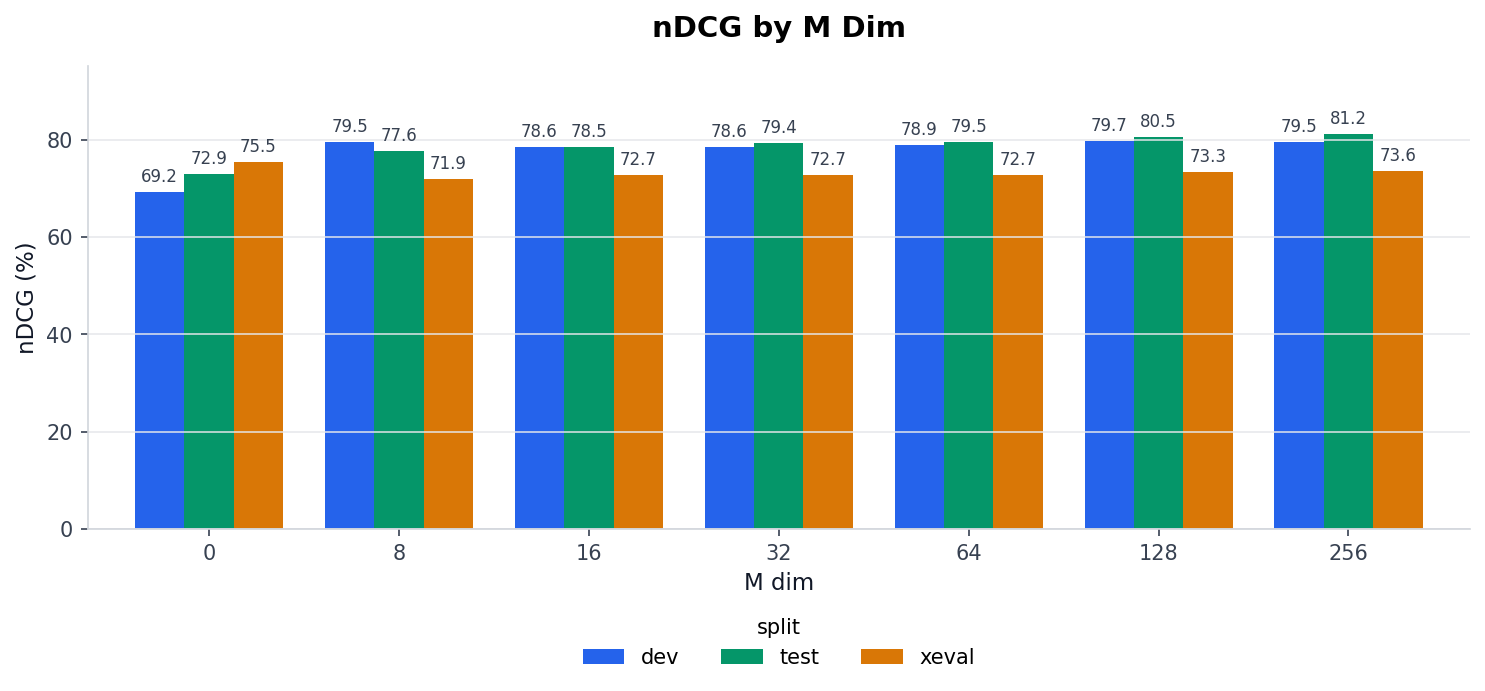

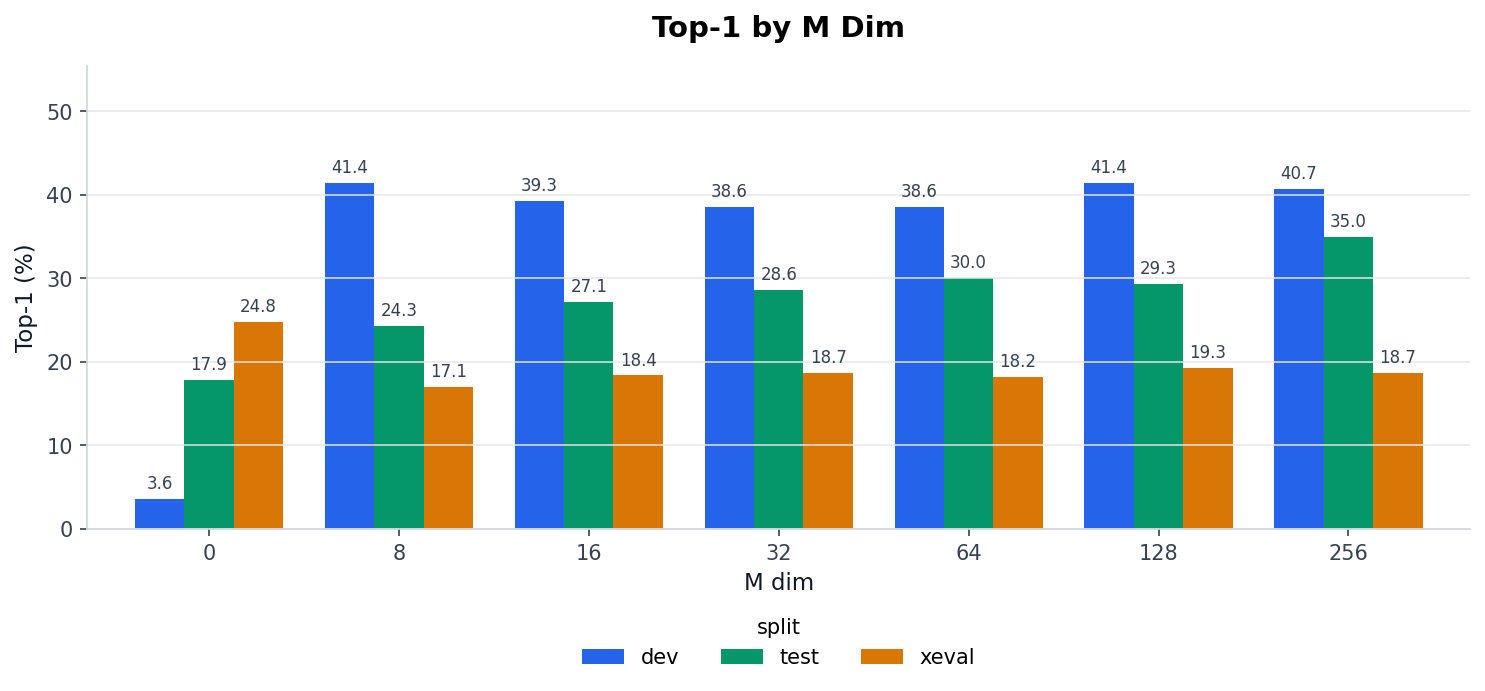

In [7]:
def finish_axis(ax, ylabel: str) -> None:
    ax.set_xlabel("M dim")
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.9)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#D1D5DB")
    ax.spines["bottom"].set_color("#D1D5DB")
    ax.legend(title="split", loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3)


def plot_metric(metric_name: str, title: str, ylabel: str) -> None:
    plot_df = aggregate_df[["m_dim", f"best_dev_{metric_name}", f"test_{metric_name}", f"xeval_{metric_name}"]].copy()
    plot_df = plot_df.rename(
        columns={
            f"best_dev_{metric_name}": "dev",
            f"test_{metric_name}": "test",
            f"xeval_{metric_name}": "xeval",
        }
    )
    plot_df[["dev", "test", "xeval"]] = plot_df[["dev", "test", "xeval"]] * 100.0

    ax = plot_df.set_index("m_dim")[["dev", "test", "xeval"]].plot(
        kind="bar",
        figsize=(10, 4.8),
        rot=0,
        width=0.78,
        color=[SPLIT_COLORS["dev"], SPLIT_COLORS["test"], SPLIT_COLORS["xeval"]],
    )

    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f", padding=3, fontsize=8, color="#374151")

    ax.set_title(title, pad=14)
    upper = float(plot_df[["dev", "test", "xeval"]].to_numpy().max())
    ax.set_ylim(0, min(100, upper + 14))
    finish_axis(ax, ylabel)
    plt.tight_layout()
    plt.show()


plot_metric("ndcg", "nDCG by M Dim", "nDCG (%)")
plot_metric("top1", "Top-1 by M Dim", "Top-1 (%)")
